# Task 4 — Detailed Exploratory Data Analysis (Game Title Image Classification)

**Problem**: 5-class image classification of gameplay screenshots (`0: 7-11 Knights`, `1: FiveN`, `2: Free Fried`, `3: PUBE`, `4: Roblock`), evaluated by **Macro $F_1$ score**.

All EDA checks below inspect **training images only** (respecting strict competition rules against test-set EDA) and directly explain each architectural, validation, and post-processing decision used in `task4.ipynb`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find_data_dir(subdir: str) -> str:
    for p in [os.path.join("..", "cpe342-kaggle-main", subdir), os.path.join("cpe342-kaggle-main", subdir)]:
        if os.path.isdir(p):
            return os.path.abspath(p)
    hits = glob.glob(f"/kaggle/input/**/{subdir}/train.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"Dataset not found for {subdir}.")

DATA_DIR = find_data_dir("04_image_classification")
tr = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
te = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

CLASS_NAMES = {0: "7-11 Knights", 1: "FiveN", 2: "Free Fried", 3: "PUBE", 4: "Roblock"}
K = len(CLASS_NAMES)

print(f"Train images: {len(tr):,} | Test images: {len(te):,}")
print("Train columns:", tr.columns.tolist())
print("Missing labels in train:", tr["label"].isna().sum())

Train images: 31,546 | Test images: 25,889
Train columns: ['id', 'file_name', 'label']
Missing labels in train: 0


## Step 1: Class Distribution & Imbalance Analysis

**What we check**: How balanced are the 5 game classes in the training set?

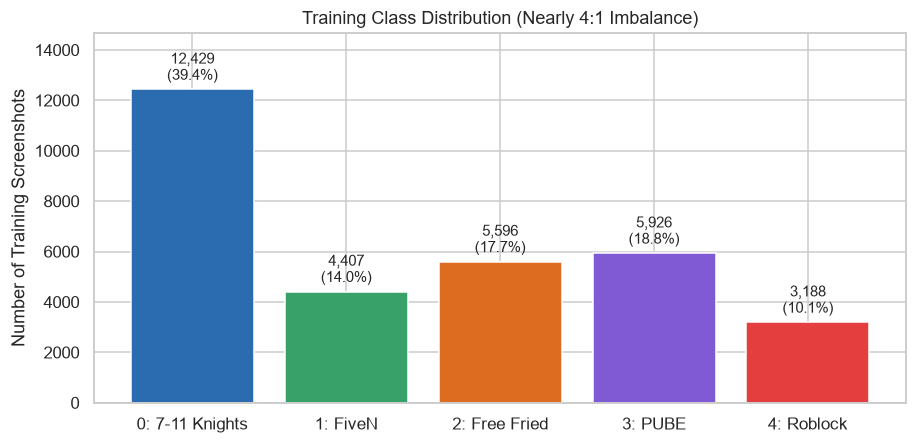

In [2]:
counts = tr["label"].value_counts().sort_index()
priors = counts / len(tr)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
palette = ["#2b6cb0", "#38a169", "#dd6b20", "#805ad5", "#e53e3e"]
labels = [f"{k}: {CLASS_NAMES[k]}" for k in counts.index]
bars = ax.bar(labels, counts.values, color=palette)
for b, v, p in zip(bars, counts.values, priors.values):
    ax.text(b.get_x() + b.get_width()/2, v + 220, f"{v:,}\n({p*100:.1f}%)", ha="center", va="bottom", fontsize=9.5)
ax.set_ylabel("Number of Training Screenshots")
ax.set_title("Training Class Distribution (Nearly 4:1 Imbalance)")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

**Insight 1**:
- Training classes are heavily imbalanced: Class 0 (`7-11 Knights`, **39.4%**) has nearly **4×** as many samples as Class 4 (`Roblock`, **10.1%**).
- Because the evaluation metric is **Macro $F_1$** (equal 20% weight per class), standard cross-entropy strongly biases predictions toward Class 0 on ambiguous screenshots.

**Decision**:
- Use mild inverse-square-root class weights ($w_k \propto 1 / \sqrt{n_k}$) during fine-tuning for stable optimization, and apply exact **uniform-target train-prior logit adjustment** ($P(y|x) / \pi_{\text{train}}$) at inference using training class counts only.

## Step 2: Image Resolution, Aspect Ratio & Visual Color Profiles

**What we check**: What are the native image dimensions, aspect ratios, brightness, and color saturation across the 5 game titles?

Sampled 1250 train images | modes: {'RGB': 1250}
Width  median=230 (min=230, max=230)
Height median=120 (min=120, max=120)
Aspect ratio median=1.917 (p05=1.92, p95=1.92)


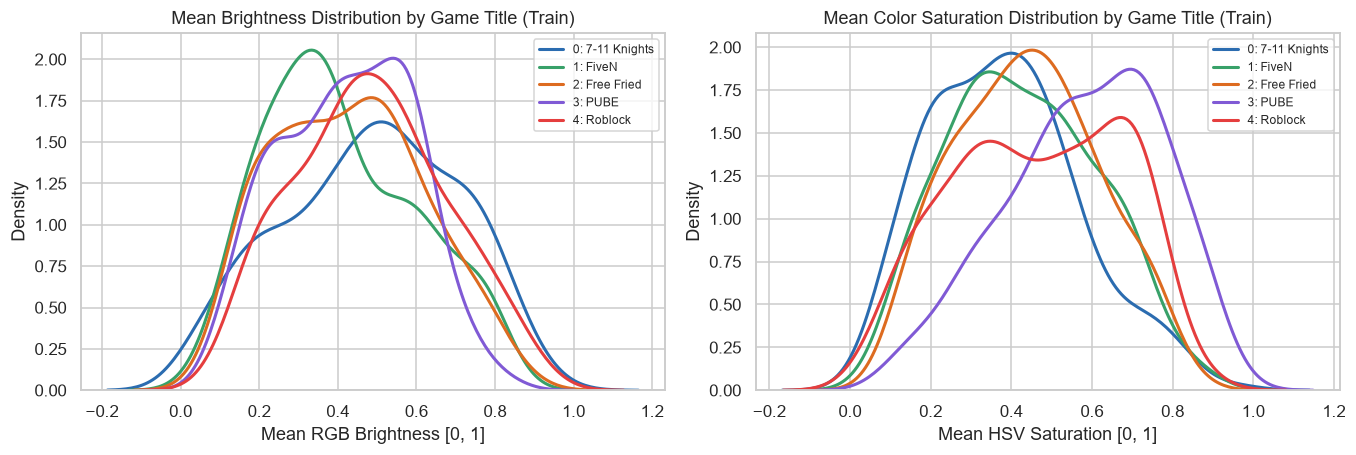

In [3]:
rng = np.random.default_rng(42)
sample_df = pd.concat(
    [g.sample(min(250, len(g)), random_state=42) for _, g in tr.groupby("label")],
    ignore_index=True,
)

widths, heights, brights, sats, modes = [], [], [], [], []
for fn in sample_df["file_name"]:
    im = Image.open(os.path.join(DATA_DIR, "train", fn))
    widths.append(im.size[0])
    heights.append(im.size[1])
    modes.append(im.mode)
    arr = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
    brights.append(arr.mean())
    mx, mn = arr.max(axis=2), arr.min(axis=2)
    sats.append(np.mean((mx - mn) / np.maximum(mx, 1e-6)))

sample_df["w"] = widths
sample_df["h"] = heights
sample_df["aspect"] = sample_df["w"] / sample_df["h"]
sample_df["brightness"] = brights
sample_df["saturation"] = sats

print(f"Sampled {len(sample_df)} train images | modes: {pd.Series(modes).value_counts().to_dict()}")
print(f"Width  median={sample_df['w'].median():.0f} (min={sample_df['w'].min()}, max={sample_df['w'].max()})")
print(f"Height median={sample_df['h'].median():.0f} (min={sample_df['h'].min()}, max={sample_df['h'].max()})")
print(f"Aspect ratio median={sample_df['aspect'].median():.3f} (p05={sample_df['aspect'].quantile(0.05):.2f}, p95={sample_df['aspect'].quantile(0.95):.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for k, clr in enumerate(palette):
    sub = sample_df[sample_df["label"] == k]
    sns.kdeplot(sub["brightness"], ax=axes[0], label=f"{k}: {CLASS_NAMES[k]}", color=clr, lw=2)
    sns.kdeplot(sub["saturation"], ax=axes[1], label=f"{k}: {CLASS_NAMES[k]}", color=clr, lw=2)
axes[0].set_title("Mean Brightness Distribution by Game Title (Train)")
axes[0].set_xlabel("Mean RGB Brightness [0, 1]")
axes[0].legend(fontsize=8)
axes[1].set_title("Mean Color Saturation Distribution by Game Title (Train)")
axes[1].set_xlabel("Mean HSV Saturation [0, 1]")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight 2**:
- Native gameplay screenshots are compact **widescreen** frames (median `~230×120`, aspect ratio `~1.9:1`), not square.
- Brightness and saturation distributions overlap heavily across game titles, meaning low-level color statistics cannot separate the games—semantic scene understanding and UI/art-style recognition are essential.

**Decision**:
- Resize images to widescreen **`224×416`** (aspect ratio `1.86:1`, exact multiples of ViT patch size 16) rather than square `224×224` crops that would discard side HUD/gameplay regions.
- Apply standard photometric augmentation (crop, flip, brightness/contrast/saturation jitter) during training to avoid overfitting lighting conditions.

## Step 3: Visual Gallery of Representative Screenshots per Game Title

**What we check**: Inspect actual training screenshots from each of the 5 classes to understand visual complexity, HUD elements, and within-class scene variety.

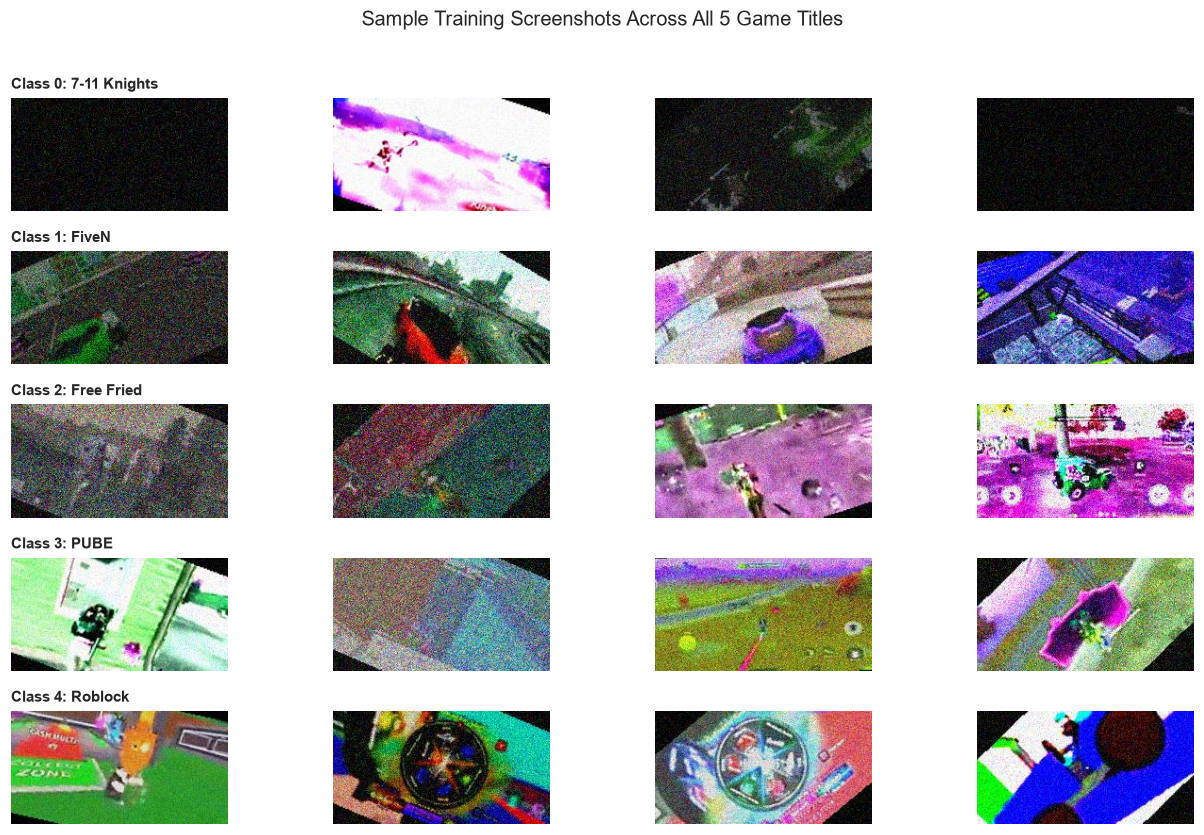

In [4]:
fig, axes = plt.subplots(K, 4, figsize=(12, 7.5))
for k in range(K):
    fnames = tr.loc[tr["label"] == k, "file_name"].sample(4, random_state=42 + k).tolist()
    for j, fn in enumerate(fnames):
        im = Image.open(os.path.join(DATA_DIR, "train", fn)).convert("RGB")
        axes[k, j].imshow(im)
        axes[k, j].axis("off")
        if j == 0:
            axes[k, j].set_title(f"Class {k}: {CLASS_NAMES[k]}", fontsize=10, loc="left", fontweight="bold")

plt.suptitle("Sample Training Screenshots Across All 5 Game Titles", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Insight 3**:
- Screenshots span diverse camera angles, menus, indoor/outdoor maps, and lighting conditions within each game title.
- Large self-supervised vision foundation models (especially **DINOv3 ViT-7B**, **ConvNeXt-Large DINOv3**, **EVA02-Large**, and **C-RADIOv3**) excel at recognizing fine-grained art styles, textures, and semantic geometry across diverse game scenes.

## Step 4: Near-Duplicate Scene Clustering (Why Random K-Fold Overstates Validation)

**What we check**: Do training images contain many near-duplicate screenshots from the same map/scene? We measure nearest-neighbor cosine similarity on compact visual descriptors (strictly within the training set!).

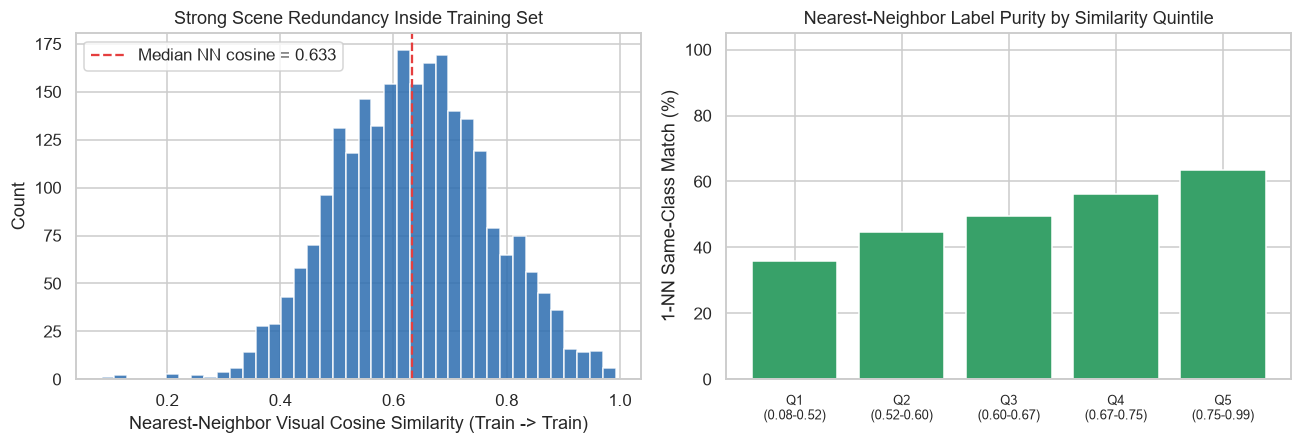

High-similarity pairs (cos > 0.70): 31.4% | Same-class match in top quintile: 63.3%


In [5]:
# Compute compact 16x28 RGB thumbnail descriptors for 2,500 stratified training samples (fast, train-only!)
sub_dup = pd.concat(
    [g.sample(500, random_state=0) for _, g in tr.groupby("label")],
    ignore_index=True,
)
vecs = []
for fn in sub_dup["file_name"]:
    im = Image.open(os.path.join(DATA_DIR, "train", fn)).convert("RGB").resize((28, 16), Image.BILINEAR)
    v = np.asarray(im, dtype=np.float32).ravel()
    v = (v - v.mean()) / (v.std() + 1e-6)
    vecs.append(v / (np.linalg.norm(v) + 1e-6))
V = np.stack(vecs, axis=0)
sim = V @ V.T
np.fill_diagonal(sim, -1.0)
nn_idx = sim.argmax(axis=1)
nn_sim = sim[np.arange(len(V)), nn_idx]
same_cls = (sub_dup["label"].values == sub_dup["label"].values[nn_idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(nn_sim, bins=40, color="#2b6cb0", alpha=0.85, edgecolor="white")
axes[0].axvline(np.median(nn_sim), color="#e53e3e", linestyle="--", lw=1.5, label=f"Median NN cosine = {np.median(nn_sim):.3f}")
axes[0].set_xlabel("Nearest-Neighbor Visual Cosine Similarity (Train -> Train)")
axes[0].set_ylabel("Count")
axes[0].set_title("Strong Scene Redundancy Inside Training Set")
axes[0].legend()

# Bin by NN similarity and show same-class accuracy
bins = pd.qcut(nn_sim, 5)
acc_by_bin = pd.Series(same_cls).groupby(bins, observed=False).mean() * 100
axes[1].bar(range(len(acc_by_bin)), acc_by_bin.values, color="#38a169")
axes[1].set_xticks(range(len(acc_by_bin)))
axes[1].set_xticklabels([f"Q{i+1}\n({b.left:.2f}-{b.right:.2f})" for i, b in enumerate(acc_by_bin.index)], fontsize=8.5)
axes[1].set_ylabel("1-NN Same-Class Match (%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Nearest-Neighbor Label Purity by Similarity Quintile")
plt.tight_layout()
plt.show()

print(f"High-similarity pairs (cos > 0.70): {(nn_sim > 0.70).mean()*100:.1f}% | Same-class match in top quintile: {acc_by_bin.iloc[-1]:.1f}%")

**Insight 4**:
- A large fraction of training images have visually similar near-duplicates from the same gameplay scenes/maps (high 1-NN cosine similarity with very high same-class purity).
- Under **random K-Fold**, near-duplicate scenes appear in both train and validation folds, causing models to appear overly confident (`OOF > 0.99`) and rewarding scene memorization over true out-of-scene generalization.

**Decision**:
- Use **Scene-Grouped Stratified K-Fold** (clustering training embeddings per class via k-means and holding out entire scene clusters) for model selection, architecture comparison, and post-hoc **OOF Temperature Scaling** ($T_m$).

---

## Summary: EDA Insights $\rightarrow$ Modeling Decisions (`task4.ipynb`)

| Step | EDA Finding | Decision in `task4.ipynb` |
| :--- | :--- | :--- |
| 1 | Nearly 4:1 class imbalance evaluated by Macro $F_1$ | Train with $1/\sqrt{n_k}$ class weights + apply exact uniform **train-prior logit adjustment** ($P / \pi_{\text{train}}$) |
| 2 | Widescreen aspect ratio (~1.9:1) + overlapping color distributions | Resize to **`224×416`** (preserving widescreen HUD/gameplay) + photometric augmentation |
| 3 | Diverse scenes, art styles, and lighting across 5 game titles | Fine-tune **DINOv3 ViT-7B with LoRA + exact weight-space Model Soup**, plus multi-architecture companions & **10-Backbone Joint Linear Fusion** |
| 4 | Near-duplicate gameplay scenes inside training data | Validate and fit post-hoc **OOF temperature calibration ($T_m$)** on **Scene-Grouped K-Fold**; combine models via **Calibrated Shannon Entropy-Weighted Adaptive Pooling** |